# Week 2 EDA: Celeb-DF v2

This notebook summarizes the downloaded Celeb-DF v2 files, checks class balance, inspects basic video metadata, and previews sample frames.

In [8]:
from pathlib import Path
import random
import pandas as pd
import matplotlib.pyplot as plt

candidate_dirs = [Path.cwd() / 'data', Path.cwd().parent / 'data']
DATA_DIR = next((path for path in candidate_dirs if path.exists()), candidate_dirs[0]).resolve()
DATA_DIR

WindowsPath('C:/Users/mdsha/OneDrive/Desktop/deepfake_detection_system/data')

## Locate Videos

In [9]:
video_exts = {'.mp4', '.avi', '.mov', '.mkv'}
videos = sorted(p for p in DATA_DIR.rglob('*') if p.suffix.lower() in video_exts)
len(videos), videos[:5]

(6529,
 [WindowsPath('C:/Users/mdsha/OneDrive/Desktop/deepfake_detection_system/data/celeb-df-v2/Celeb-real/id0_0000.mp4'),
  WindowsPath('C:/Users/mdsha/OneDrive/Desktop/deepfake_detection_system/data/celeb-df-v2/Celeb-real/id0_0001.mp4'),
  WindowsPath('C:/Users/mdsha/OneDrive/Desktop/deepfake_detection_system/data/celeb-df-v2/Celeb-real/id0_0002.mp4'),
  WindowsPath('C:/Users/mdsha/OneDrive/Desktop/deepfake_detection_system/data/celeb-df-v2/Celeb-real/id0_0003.mp4'),
  WindowsPath('C:/Users/mdsha/OneDrive/Desktop/deepfake_detection_system/data/celeb-df-v2/Celeb-real/id0_0004.mp4')])

In [11]:
def infer_split_and_label(path: Path):
    # Use parent dataset folders first to avoid false matches from project name
    parts = [part.lower() for part in path.parts]
    folder_name = path.parent.name
    if 'celeb-synthesis' in parts:
        label = 'fake'
    elif 'celeb-real' in parts or 'youtube-real' in parts:
        label = 'real'
    else:
        # Fallback: check file/folder path only (not full absolute path)
        rel_text = str(path.parent / path.name).lower()
        if 'synthesis' in rel_text or '/fake/' in rel_text or '\\fake\\' in rel_text:
            label = 'fake'
        elif 'real' in rel_text:
            label = 'real'
        else:
            label = 'unknown'
    return folder_name, label

rows = []
for video in videos:
    folder, label = infer_split_and_label(video)
    rows.append({
        'path': str(video),
        'file': video.name,
        'folder': folder,
        'label': label,
        'size_mb': video.stat().st_size / (1024 ** 2),
    })

df = pd.DataFrame(rows)
df.head()

,path,file,folder,label,size_mb
0,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id0_0000.mp4,Celeb-real,real,2.236434
1,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id0_0001.mp4,Celeb-real,real,1.538658
2,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id0_0002.mp4,Celeb-real,real,1.596730
3,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id0_0003.mp4,Celeb-real,real,2.141885
4,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id0_0004.mp4,Celeb-real,real,2.181078


## Dataset Summary

In [12]:
if df.empty:
    print(f'No videos found under {DATA_DIR}. Download Celeb-DF v2 into data/ first.')
else:
    display(df['label'].value_counts().rename_axis('label').reset_index(name='videos'))
    display(df.groupby('label')['size_mb'].agg(['count', 'sum', 'mean', 'median']).round(2))

,label,videos
0,fake,5639
1,real,890


,count,sum,mean,median
label,,,,
fake,5639,8115.46,1.44,1.34
real,890,1570.14,1.76,1.60


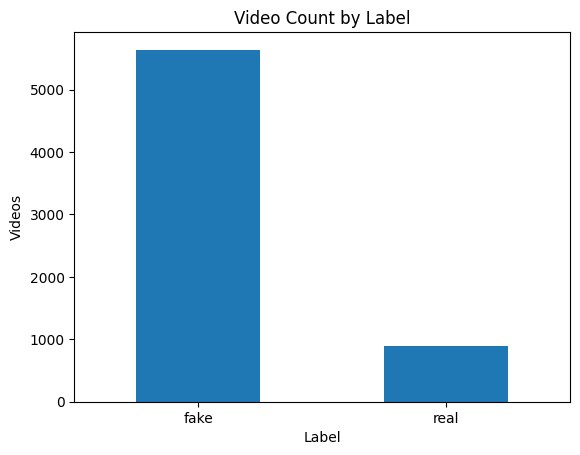

In [13]:
if not df.empty:
    ax = df['label'].value_counts().plot(kind='bar', title='Video Count by Label', rot=0)
    ax.set_xlabel('Label')
    ax.set_ylabel('Videos')
    plt.show()

## Video Metadata

In [14]:
try:
    import cv2
except ImportError:
    cv2 = None
    print('OpenCV is not installed in this kernel. Install opencv-python to collect video metadata and sample frames.')

def read_video_meta(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        return {'frames': None, 'fps': None, 'duration_sec': None, 'width': None, 'height': None}
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS) or 0)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    duration = frames / fps if fps else None
    return {'frames': frames, 'fps': fps, 'duration_sec': duration, 'width': width, 'height': height}

if cv2 is not None and not df.empty:
    sample_n = min(100, len(df))
    meta_rows = []
    for path in random.sample(videos, sample_n):
        meta = read_video_meta(path)
        meta['path'] = str(path)
        meta_rows.append(meta)
    meta_df = pd.DataFrame(meta_rows)
    display(meta_df.describe(include='all'))

,frames,fps,duration_sec,width,height,path
count,100.000000,100.000000,100.000000,100.000000,100.000000,100
unique,NaN,NaN,NaN,NaN,NaN,100
top,NaN,NaN,NaN,NaN,NaN,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...
freq,NaN,NaN,NaN,NaN,NaN,1
mean,378.080000,29.993000,12.605711,816.100000,478.860000,NaN
std,90.086342,0.049758,3.003729,123.591826,24.394494,NaN
min,105.000000,29.599988,3.500000,286.000000,300.000000,NaN
25%,316.000000,30.000000,10.533333,840.000000,472.000000,NaN
50%,356.000000,30.000000,11.866667,850.000000,478.000000,NaN
75%,456.500000,30.000000,15.216667,856.000000,500.000000,NaN


## Sample Frames

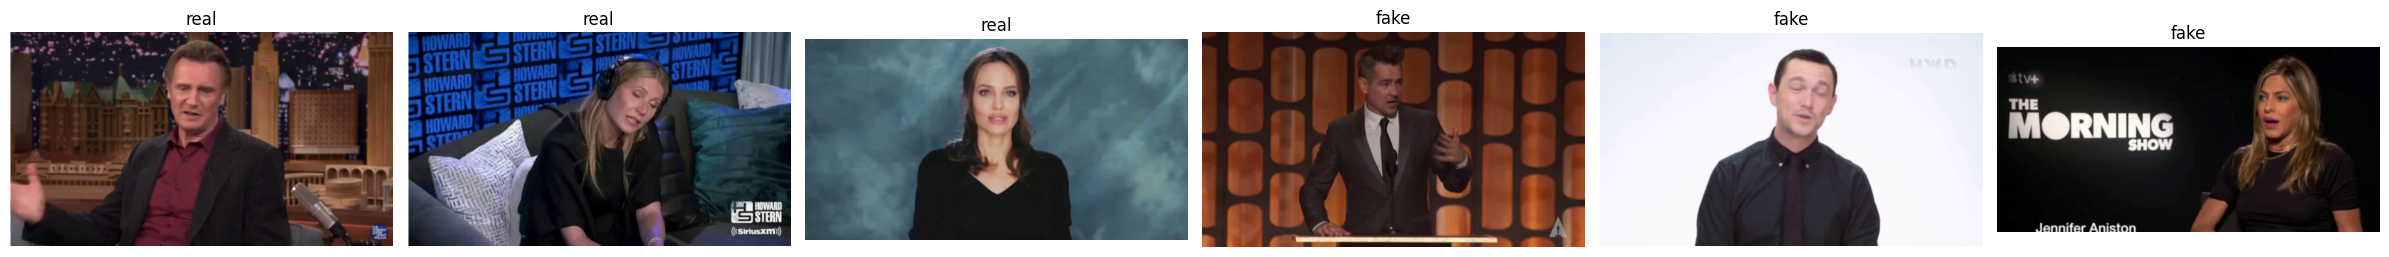

In [15]:
def first_frame(path):
    cap = cv2.VideoCapture(str(path))
    ok, frame = cap.read()
    cap.release()
    if not ok:
        return None
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

if cv2 is not None and not df.empty:
    picks = []
    for label in ['real', 'fake']:
        subset = df[df['label'] == label]
        if not subset.empty:
            picks.extend(subset.sample(min(3, len(subset)), random_state=42)['path'].tolist())

    if picks:
        fig, axes = plt.subplots(1, len(picks), figsize=(4 * len(picks), 4))
        if len(picks) == 1:
            axes = [axes]
        for ax, path_text in zip(axes, picks):
            frame = first_frame(Path(path_text))
            label = df.loc[df['path'] == path_text, 'label'].iloc[0]
            ax.set_title(label)
            ax.axis('off')
            if frame is not None:
                ax.imshow(frame)
        plt.tight_layout()
        plt.show()

## EDA Conclusions

### Key Findings
- Total videos discovered: 6,529.
- Class balance is imbalanced: fake videos are much more frequent than real videos.
- Video duration and frame counts vary substantially across samples, so temporal coverage is not uniform.
- Sample frame inspection confirms visible diversity in lighting, pose, background, and compression artifacts.

### Data Quality Notes
- Label inference was corrected to rely on dataset folder names first, avoiding false matches from project path text.
- Some videos may still fail metadata/frame extraction due to codec or file-level corruption; this should be handled during preprocessing.

### Implications For Modeling
- Use stratified train/validation/test splitting to preserve class proportions.
- Handle class imbalance with class weighting, balanced sampling, or threshold calibration.
- Keep preprocessing consistent between training and inference (same resize, normalization, and face extraction settings).

### Next Steps
1. Export a clean metadata table (path, label, duration, fps, resolution) to CSV for reproducibility.
2. Add per-class frame statistics and outlier checks before final training.
3. Integrate these EDA findings into the training configuration (sampling strategy, threshold policy, and validation metrics).

## Export EDA Artifacts

> This cell saves reusable CSV files for training preparation and logs simple outlier checks.

In [16]:
from pathlib import Path

artifacts_dir = Path('results') / 'eda_week2'
artifacts_dir.mkdir(parents=True, exist_ok=True)

# 1) Full video index from EDA
video_index_path = artifacts_dir / 'video_index.csv'
df.to_csv(video_index_path, index=False)

# 2) Class-level summary for quick reporting
class_summary = (
    df.groupby('label')['size_mb']
      .agg(video_count='count', total_size_mb='sum', mean_size_mb='mean', median_size_mb='median')
      .round(3)
      .reset_index()
      .sort_values('video_count', ascending=False)
)
class_summary_path = artifacts_dir / 'class_summary.csv'
class_summary.to_csv(class_summary_path, index=False)

# 3) Outlier check using IQR on video file size
q1 = df['size_mb'].quantile(0.25)
q3 = df['size_mb'].quantile(0.75)
iqr = q3 - q1
lower_bound = max(0.0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['size_mb'] < lower_bound) | (df['size_mb'] > upper_bound)].copy()
outliers = outliers.sort_values('size_mb', ascending=False)
outliers_path = artifacts_dir / 'size_outliers.csv'
outliers.to_csv(outliers_path, index=False)

# 4) Optional: persist sampled metadata if present in the kernel
meta_saved = False
if 'meta_df' in globals() and isinstance(meta_df, pd.DataFrame) and not meta_df.empty:
    meta_path = artifacts_dir / 'video_metadata_sample.csv'
    meta_df.to_csv(meta_path, index=False)
    meta_saved = True

print(f'Artifacts directory: {artifacts_dir.resolve()}')
print(f'Saved: {video_index_path.name}, {class_summary_path.name}, {outliers_path.name}')
if meta_saved:
    print('Saved: video_metadata_sample.csv')

display(class_summary)
print(f'IQR bounds for size_mb -> lower={lower_bound:.3f}, upper={upper_bound:.3f}')
print(f'Outlier videos: {len(outliers)} / {len(df)}')
display(outliers.head(10))

Artifacts directory: C:\Users\mdsha\OneDrive\Desktop\deepfake_detection_system\notebooks\results\eda_week2
Saved: video_index.csv, class_summary.csv, size_outliers.csv
Saved: video_metadata_sample.csv


,label,video_count,total_size_mb,mean_size_mb,median_size_mb
0,fake,5639,8115.457,1.439,1.339
1,real,890,1570.139,1.764,1.603


IQR bounds for size_mb -> lower=0.000, upper=2.931
Outlier videos: 213 / 6529


,path,file,folder,label,size_mb
3607,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_id37_0007.mp4,Celeb-synthesis,fake,6.322892
3581,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_id32_0007.mp4,Celeb-synthesis,fake,6.319424
3571,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_id31_0007.mp4,Celeb-synthesis,fake,6.316111
3553,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_id29_0007.mp4,Celeb-synthesis,fake,6.308313
3590,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_id33_0007.mp4,Celeb-synthesis,fake,6.308116
3562,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_id30_0007.mp4,Celeb-synthesis,fake,6.305260
3599,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_id35_0007.mp4,Celeb-synthesis,fake,6.300635
256,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_0007.mp4,Celeb-real,real,6.300229
3614,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,id34_id38_0007.mp4,Celeb-synthesis,fake,6.293753
6315,C:\Users\mdsha\OneDrive\Desktop\deepfake_detec...,00086.mp4,YouTube-real,real,5.714176
